# Teaching a student

The simplest teaching: while a student works on a training puzzle, a teacher who knows the optimal moves (breadth-first search) may show it the next optimal move, which the student then plays. Teachers differ only in *when* they do (`scripts/teach.py`):

- **random p** - on each turn, with probability p (`TEACH_PROBABILITIES`). p = 0 never teaches: the student learns only from its own attempts. p = 1 shows every move: the student only watches - pure imitation of the teacher.
- **correct mistakes** - lets the student play, and shows the optimal move only when the move it is about to make isn't optimal. The student acts on its own boards (as in DAgger), yet every mistake is corrected; it needs teaching less as it improves. It sees the move the student *intends* before it is played - an idealization.
- **correct after mistake** - the realistic version: every move the student makes stands; after one that wasn't optimal, the teacher shows the optimal move from the board it led to, on the student's next turn. Its printout reports what the mistakes were like: whether they took the board further from the goal or sideways, how often undoing the mistake was optimal, and how often the move shown was that undo.

Teachers also differ in how much they teach, so besides trajectories over rounds, the plots show solve rate against the **teaching budget**: the total number of moves shown during training.

The student is **pure intuition**: its network picks a move every turn - sampled from its move probabilities while learning, its top move when tested - avoiding the last `MEMORY` boards; no search. It learns by expert iteration (`rl.expert_iteration`): each round it attempts every training puzzle with its teacher, then trains on what the attempts showed - the moves of its solved attempts (loops cut out) and every move the teacher showed, solved or not - and starts the next round from the result.

After each round, the student is **tested without a teacher** on held-out puzzles. That gives its learning trajectory under each teacher. The goal is eventually an adaptive teacher that learns a schedule; these fixed schedules are the baselines.

In [1]:
import sys
sys.path.append("../scripts")
import json
import os
import random
import statistics

import matplotlib.pyplot as plt
import torch
from tqdm import tqdm

import rl
import teach

## Parameters

`N_TRAIN_PER_BIN = 100` gives 500 training puzzles; each of the `ROUNDS` rounds makes `ATTEMPTS_PER_PUZZLE` attempts per training and validation puzzle (with the teacher), then trains for up to `EPOCHS` epochs, stopping after `PATIENCE` without improvement on validation. Only each round's kept network is saved, to `CHECKPOINT_ROOT/<teacher>/`. `RUN_NAME` names this run's checkpoint folder and plots, so runs with different teachers don't overwrite each other.

`EXPLORE_TEMPERATURE` is how freely the student samples its moves while learning (1 = in proportion to its move probabilities). Testing always uses its top move, so one test attempt per puzzle is enough.

In [2]:
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
BINS = [(1, 8), (9, 12), (13, 16), (17, 20)]  # distance-to-goal bins, sampled evenly
N_TRAIN_PER_BIN = 100
N_VAL_PER_BIN = 10  # validation puzzles: pick each round's best epoch
N_TEST_PER_BIN = 20  # test puzzles: the student is tested on them, never taught on them

TEACH_PROBABILITIES = [0.1]  # chance a random teacher shows the optimal move on each turn
TEACHERS = [teach.Random(p) for p in TEACH_PROBABILITIES] + [teach.CorrectMistakes(), teach.CorrectAfterMistake()]
RUN_NAME = "mistakes"  # names the checkpoint folder and plots of this run

ROUNDS = 3
ATTEMPTS_PER_PUZZLE = 2
EXPLORE_TEMPERATURE = 1.0
MEMORY = 10  # recent boards the student avoids returning to
MAX_STEPS = 200
EPOCHS = 10
PATIENCE = 3
CHECKPOINT_ROOT = os.path.join("../models/teach", RUN_NAME)

## Loading data

Test, validation and training puzzles are disjoint samples from `rush_nw.txt`, evenly spread over the distance bins. All teachers teach on the same training puzzles.

In [3]:
pool = rl.load_puzzle_pool("../data/rush_nw.txt")
test = rl.sample_by_distance(pool, BINS, N_TEST_PER_BIN, seed=SEED)
val = rl.sample_by_distance(pool, BINS, N_VAL_PER_BIN, seed=SEED + 1, exclude=[s for _, s in test])
train = rl.sample_by_distance(pool, BINS, N_TRAIN_PER_BIN, seed=SEED + 2, exclude=[s for _, s in test + val])
print(f"{len(train)} training, {len(val)} validation, {len(test)} test puzzles")

400 training, 40 validation, 80 test puzzles


## Teaching

One fresh student per teacher, all starting from the same initial weights. The printout per round: how many training attempts the student solved, the share of its moves the teacher showed, how many boards it learned from, and its validation agreement (with that round's own attempts) at the epoch it kept.

In [4]:
def checkpoint_dir(teacher):
    return os.path.join(CHECKPOINT_ROOT, teacher.name.replace(" ", "_"))


histories = {}
for teacher in TEACHERS:
    print(f"=== teacher: {teacher.name} ===")
    random.seed(SEED)
    torch.manual_seed(SEED)
    student = rl.PolicyAgent(device=DEVICE)
    histories[teacher.name] = rl.expert_iteration(
        student, [s for _, s in train], [s for _, s in val], rounds=ROUNDS, n_attempts=ATTEMPTS_PER_PUZZLE,
        max_steps=MAX_STEPS, seed=SEED, checkpoint_dir=checkpoint_dir(teacher), checkpoint_epochs=False,
        student="intuition", teacher=teacher, explore=EXPLORE_TEMPERATURE, memory=MEMORY,
        epochs=EPOCHS, patience=PATIENCE)
    for r in histories[teacher.name]:
        print(f"  round {r['round']}: solved {r['solved']}/{r['attempts']} training attempts, "
              f"{r['taught_moves']} of {r['moves']} moves shown ({r['taught']:.0%}), {r['boards']} boards learned from, "
              f"validation agreement {r['agreement']:.0%} (epoch {r['best_epoch']})")
        c = r["teacher_counts"]
        if "mistakes_worse" in c or "mistakes_sideways" in c:
            mistakes = c.get("mistakes_worse", 0) + c.get("mistakes_sideways", 0)
            corrections = max(c.get("corrections", 0), 1)
            print(f"    {mistakes} mistakes: {c.get('mistakes_worse', 0)} took the board further from the goal, "
                  f"{c.get('mistakes_sideways', 0)} sideways; undoing was optimal for "
                  f"{c.get('undo_optimal', 0) / corrections:.0%} of corrections, and the move shown was the undo "
                  f"for {c.get('shown_undo', 0) / corrections:.0%}")

=== teacher: random 0.1 ===


training epochs:  40%|████      | 4/10 [00:50<01:15, 12.66s/it, agreement=28.4%]

  round 1: solved 571/800 training attempts, 9737 of 96078 moves shown (10%), 33557 boards learned from, validation agreement 23% (epoch 5)
  round 2: solved 765/800 training attempts, 4942 of 49130 moves shown (10%), 29292 boards learned from, validation agreement 27% (epoch 1)
  round 3: solved 775/800 training attempts, 4198 of 42391 moves shown (10%), 26490 boards learned from, validation agreement 30% (epoch 2)
=== teacher: correct mistakes ===



training epochs:  70%|███████   | 7/10 [00:20<00:08,  2.89s/it, agreement=69.0%]

  round 1: solved 800/800 training attempts, 7390 of 10024 moves shown (74%), 8022 boards learned from, validation agreement 59% (epoch 7)
  round 2: solved 800/800 training attempts, 584 of 10024 moves shown (6%), 6870 boards learned from, validation agreement 66% (epoch 2)
  round 3: solved 800/800 training attempts, 422 of 10024 moves shown (4%), 6427 boards learned from, validation agreement 69% (epoch 5)
=== teacher: correct after mistake ===



training epochs:  30%|███       | 3/10 [00:19<00:46,  6.66s/it, agreement=46.8%]

  round 1: solved 800/800 training attempts, 10095 of 23786 moves shown (42%), 19705 boards learned from, validation agreement 32% (epoch 5)
    10095 mistakes: 3667 took the board further from the goal, 6428 sideways; undoing was optimal for 36% of corrections, and the move shown was the undo for 20%
  round 2: solved 800/800 training attempts, 5725 of 17381 moves shown (33%), 14695 boards learned from, validation agreement 41% (epoch 1)
    5725 mistakes: 1632 took the board further from the goal, 4093 sideways; undoing was optimal for 29% of corrections, and the move shown was the undo for 16%
  round 3: solved 800/800 training attempts, 3964 of 14943 moves shown (27%), 12664 boards learned from, validation agreement 49% (epoch 1)
    3964 mistakes: 955 took the board further from the goal, 3009 sideways; undoing was optimal for 24% of corrections, and the move shown was the undo for 13%


## Learning trajectories

Each teacher's student after every round (round 0 = untrained), tested on the test puzzles with no teacher: one top-move-every-turn attempt per puzzle (`rl.evaluate_intuition`). Error bands are standard errors across puzzles; moves / optimal is over solved puzzles.

The last panel is the teaching budget: each point is a round's tested solve rate, placed at the number of moves the teacher had shown on training attempts up to then - how much teaching bought how much skill.

In [5]:
def mean_se(values):
    """(mean, standard error) of the non-nan values."""
    values = [v for v in values if v == v]
    if not values:
        return float("nan"), float("nan")
    se = statistics.stdev(values) / len(values) ** 0.5 if len(values) > 1 else float("nan")
    return statistics.mean(values), se


def summarize(runs):
    """Solve rate and moves / optimal (mean, standard error), overall and per distance bin."""
    out = {"solve rate": mean_se([float(r["solved"]) for r in runs]),
           "moves / optimal": mean_se([r["moves"] / r["distance"] for r in runs if r["solved"]])}
    for lo, hi in BINS:
        out[(lo, hi)] = mean_se([float(r["solved"]) for r in runs if lo <= r["distance"] <= hi])
    return out


trajectories = {}  # teacher -> [(round, summarize(...))]
for teacher in TEACHERS:
    with open(os.path.join(checkpoint_dir(teacher), "manifest.json")) as f:
        kept = sorted((m for m in json.load(f) if m["kept"]), key=lambda m: m["round"])
    trajectories[teacher.name] = []
    for m in tqdm(kept, desc=f"testing ({teacher.name})"):
        checkpoint = rl.PolicyAgent.load(os.path.join(checkpoint_dir(teacher), m["file"]))
        runs = rl.evaluate_intuition(checkpoint, test, memory=MEMORY, max_steps=MAX_STEPS)
        trajectories[teacher.name].append((m["round"], summarize(runs)))

for name, points in trajectories.items():
    final_round, final = points[-1]
    (rate, se), (ratio, ratio_se) = final["solve rate"], final["moves / optimal"]
    print(f"{name:<12} after round {final_round}: solved {rate:.0%} ± {se:.0%}, {ratio:.1f} ± {ratio_se:.1f}x optimal")

testing (correct after mistake): 100%|██████████| 4/4 [00:24<00:00,  6.08s/it]

random 0.1   after round 3: solved 66% ± 5%, 1.4 ± 0.1x optimal
correct mistakes after round 3: solved 84% ± 4%, 1.3 ± 0.0x optimal
correct after mistake after round 3: solved 69% ± 5%, 1.2 ± 0.0x optimal


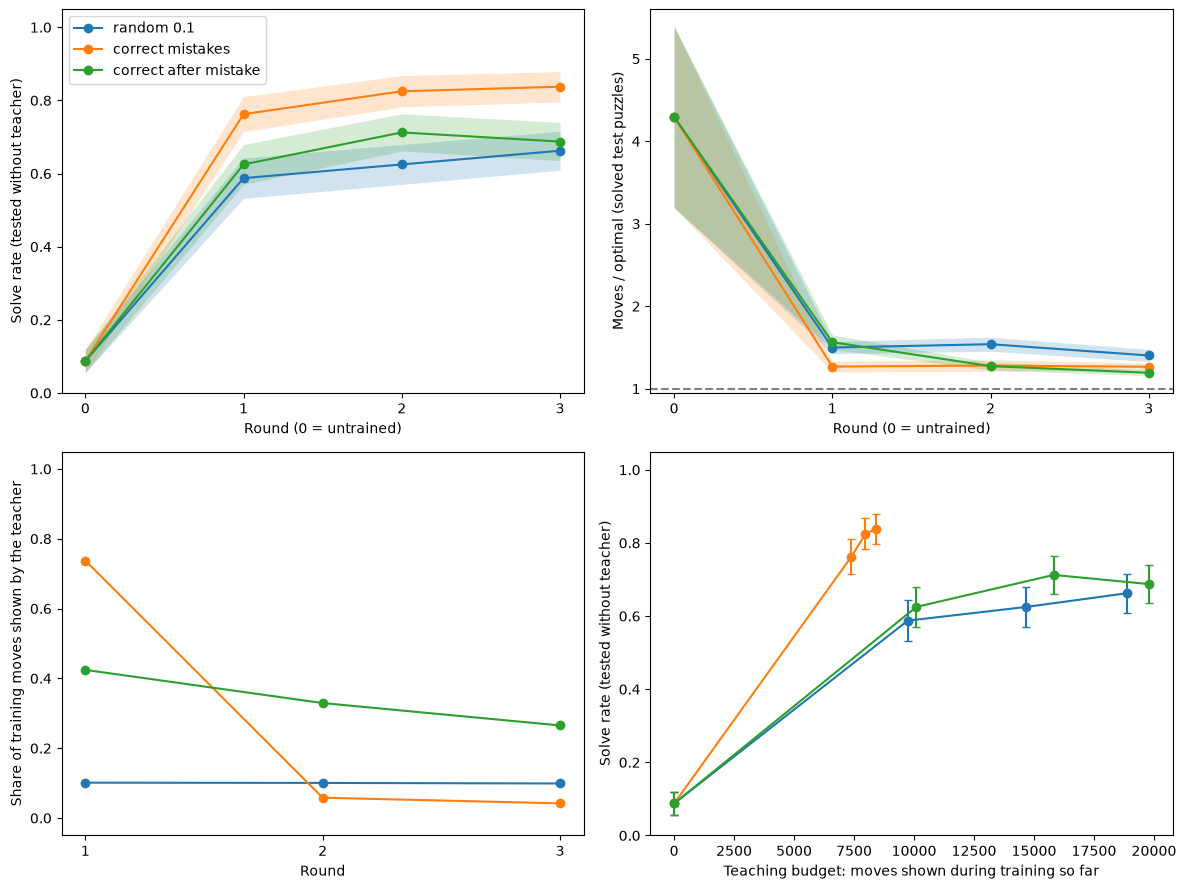

In [6]:
colors = {t.name: f"C{i}" for i, t in enumerate(TEACHERS)}
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
(ax_rate, ax_moves), (ax_share, ax_budget) = axes
for name, points in trajectories.items():
    rounds = [r for r, _ in points]
    for ax, key in ((ax_rate, "solve rate"), (ax_moves, "moves / optimal")):
        ms = [s[key][0] for _, s in points]
        ses = [s[key][1] if s[key][1] == s[key][1] else 0.0 for _, s in points]
        ax.plot(rounds, ms, marker="o", color=colors[name], label=name)
        ax.fill_between(rounds, [m - e for m, e in zip(ms, ses)], [m + e for m, e in zip(ms, ses)],
                        color=colors[name], alpha=0.2, linewidth=0)
    history = histories[name]
    ax_share.plot([h["round"] for h in history], [h["taught"] for h in history], marker="o", color=colors[name],
                  label=name)
    # teaching budget: moves shown on training attempts so far (0 before round 1)
    budget = [0]
    for h in history:
        budget.append(budget[-1] + h["taught_moves"])
    by_round = dict(points)
    xs = [budget[r] for r in rounds]
    ms = [by_round[r]["solve rate"][0] for r in rounds]
    ses = [by_round[r]["solve rate"][1] if by_round[r]["solve rate"][1] == by_round[r]["solve rate"][1] else 0.0
           for r in rounds]
    ax_budget.errorbar(xs, ms, yerr=ses, marker="o", capsize=3, color=colors[name], label=name)
ax_rate.set_ylabel("Solve rate (tested without teacher)")
ax_rate.set_ylim(0, 1.05)
ax_moves.set_ylabel("Moves / optimal (solved test puzzles)")
ax_moves.axhline(1.0, color="gray", linestyle="--")
for ax in (ax_rate, ax_moves):
    ax.set_xlabel("Round (0 = untrained)")
    ax.set_xticks(range(ROUNDS + 1))
ax_share.set_ylabel("Share of training moves shown by the teacher")
ax_share.set_ylim(-0.05, 1.05)
ax_share.set_xlabel("Round")
ax_share.set_xticks(range(1, ROUNDS + 1))
ax_budget.set_ylabel("Solve rate (tested without teacher)")
ax_budget.set_ylim(0, 1.05)
ax_budget.set_xlabel("Teaching budget: moves shown during training so far")
ax_rate.legend()
plt.tight_layout()
os.makedirs("../visualization", exist_ok=True)
plt.savefig(f"../visualization/teaching_{RUN_NAME}.png")
plt.show()

The same trajectories by puzzle difficulty: solve rate (tested without teacher) per distance bin.

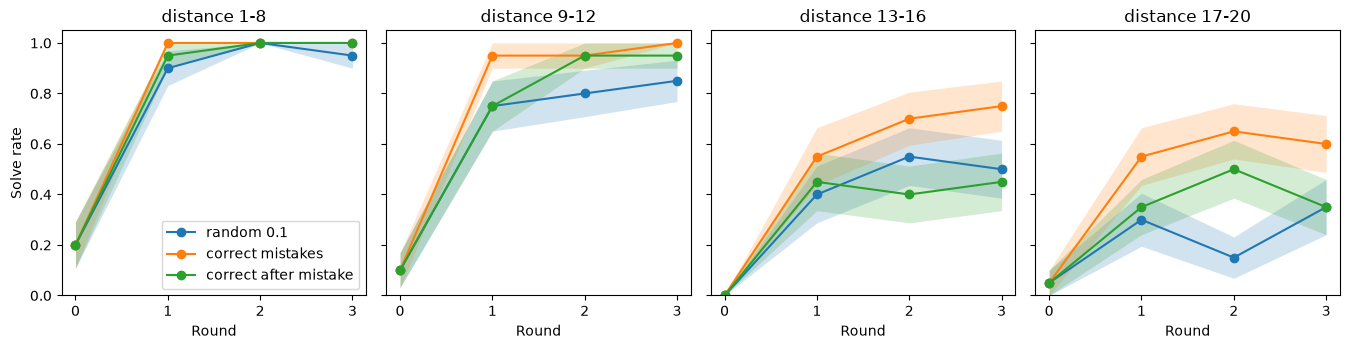

In [7]:
fig, axes = plt.subplots(1, len(BINS), figsize=(3.4 * len(BINS), 3.6), sharey=True)
for ax, (lo, hi) in zip(axes, BINS):
    for name, points in trajectories.items():
        rounds = [r for r, _ in points]
        ms = [s[(lo, hi)][0] for _, s in points]
        ses = [s[(lo, hi)][1] if s[(lo, hi)][1] == s[(lo, hi)][1] else 0.0 for _, s in points]
        ax.plot(rounds, ms, marker="o", color=colors[name], label=name)
        ax.fill_between(rounds, [m - e for m, e in zip(ms, ses)], [m + e for m, e in zip(ms, ses)],
                        color=colors[name], alpha=0.2, linewidth=0)
    ax.set_title(f"distance {lo}-{hi}")
    ax.set_xlabel("Round")
    ax.set_xticks(range(ROUNDS + 1))
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Solve rate")
axes[0].legend()
plt.tight_layout()
plt.savefig(f"../visualization/teaching_{RUN_NAME}_by_distance.png")
plt.show()